In [1]:
import os
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
from astropy.convolution import convolve, Gaussian1DKernel, Box1DKernel
import matplotlib as mpl
from scipy.signal import find_peaks
from pathlib import Path


%matplotlib inline
# Set the default font family to serif
plt.rcParams['font.family'] = 'serif'
mpl.rcParams['pdf.fonttype'] = 42   # keeps text as text in PDF
mpl.rcParams['svg.fonttype'] = 'none'  # keeps text as text in SVG
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
def scan_data_1(date, time):
    '''
    Function scan_data: opens a "Scan Data" file and puts into a pandas dataframe
    Dariables: date - string; time - string
    '''
    scan_dir = '/content/drive/MyDrive/Data/'
    filepath = scan_dir + '/' + date + '/' + time + ' Scan Data.csv'
    df = pd.read_csv(filepath, delimiter=',', skiprows=6)
    with open(filepath, 'r') as file:
        csv_reader = csv.reader(file)
        i = 0
        for row in csv_reader:
            if i < 6:
                print(row)
                i = i+1
        print()

#     display(df)
#     print(df.columns)      # get names of all the columns

    return df

def scan_data(date_time_list):
    '''
    Function scan_data: opens multiple "Scan Data" files and stores them as DataFrames in a list.

    Parameters:
        date_time_list: list of 2-element sets or tuples
                        Example: [("2025-10-20", "13-00-00"), ("2025-10-21", "14-30-00")]

    Returns:
        dfs: list of pandas DataFrames
    '''
    scan_dir = '/content/drive/MyDrive/Data/'
    dfs = []

    for entry in date_time_list:
        # convert set to list to unpack
        date, time = list(entry)
        filepath = f"{scan_dir}/{date}/{time} Scan Data.csv"

        df = pd.read_csv(filepath, delimiter=',', skiprows=6)
        dfs.append(df)

        with open(filepath, 'r') as file:
            csv_reader = csv.reader(file)
            print(f"Header for {date} {time}:")
            for i, row in enumerate(csv_reader):
                if i >= 6:
                    break
                print(row)
            print()

    return dfs




def plot_water():
    '''
    Function plot_water: plots water vapor THz absorption lines
    '''
    plt.axvline(556.936, color='red', lw=3, ls='dotted', label='water vapor') # label='H$_2$O')
    plt.axvline(752.033, color='red', lw=3, ls='dotted')
    plt.axvline(1097.364, color='red', lw=3, ls='dotted')
    plt.axvline(1113.342, color='red', lw=3, ls='dotted')
    plt.axvline(1162.911, color='red', lw=3, ls='dotted')
    plt.axvline(1207.638, color='red', lw=3, ls='dotted')
    plt.axvline(1228.788, color='red', lw=3, ls='dotted')
    plt.axvline(1410.618, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1602.219, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1661.007, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1669.904, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1716.769, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1794.788, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1797.158, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1867.748, color='grey', lw=0.5, ls='dotted')
    plt.axvline(1919.359, color='grey', lw=0.5, ls='dotted')
    return

def get_freq(df):
    '''
    Input: pandas dataframe
    Output: Frequency column from a "Scan Data" file [GHz]
    '''
    return df[df.columns[0]]

def get_volt(df):
    '''
    Input: pandas dataframe
    Output: Voltage column from a "Scan Data" file [GHz]
    '''
    return df[df.columns[2]]

def get_pow(df):
    '''
    Input: pandas dataframe
    Output: Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[3]]

def get_smooth(df):
    '''
    Input: pandas dataframe
    Output: Smoothed Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[4]]

def get_bkd(df):
    '''
    Input: pandas dataframe
    Output: Background Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[6]]

def smooth_bkd(df):
    '''
    Input: pandas dataframe
    Output: Smoothed Background Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[7]]

def get_norm(df):
    '''
    Input: pandas dataframe
    Output: Normalized Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[9]]

def get_norm_smooth(df):
    '''
    Input: pandas dataframe
    Output: Normalized Smoothed Average Power column from a "Scan Data" file [arb]
    '''
    return df[df.columns[10]]

def gauss_smooth(val, df):
    '''
    Function gauss_smooth: performs 1D gaussian convolution of
        Average Power column from a "Scan Data" file [arb]
    Inputs:
        val = smooth amount
        df = pandas dataframe
    Output: smoothed average power [arb]
    '''
    gauss_kernel = Gaussian1DKernel(val)
    return convolve(df[df.columns[3]], gauss_kernel)

def gauss_bkd(val, df):
    '''
    Function gauss_bkd: performs 1D gaussian convolution of
        Background Average Power column from a "Scan Data" file [arb]
    Inputs:
        val = smooth amount
        df = pandas dataframe
    Output: smoothed background average power
    '''
    gauss_kernel = Gaussian1DKernel(val)
    return convolve(df[df.columns[6]], gauss_kernel)

def gaussian(x, peak, center, fwhm):
    '''
    Function gaussian: creates a normal distribution in terms of the FWHM
    Inputs:
        x = array of x values
        peak = peak of the curve [unitless]
        center = central frequency [GHz]
        fwhm = full width half max [GHz]
    '''
    f = peak * (np.e**((-4*np.log(2)*(x-center)**2)/fwhm**2))
    return f

def erf(peak, fwhm):
    '''
    Function erf: calculates the error function (integral of the gaussian)
    Inputs:
        peak = peak of the curve [unitless]
        fwhm = full width half max [GHz]
    Output: error function
    '''
    f = (np.sqrt(np.pi)*peak*fwhm)/(2*np.sqrt(np.log(2)))
    return f

def plot_all(dfs, res, stp, d, date, scan, smooth=2):
    '''
    Plots THz transmission voltage vs frequency for each scan dataframe separately.

    Parameters:
        dfs : list of pandas DataFrames
              Each DataFrame should have frequency and voltage columns.
        res : float or int
              Resolution in MHz
        stp : float or int
              Step size in ms
        d   : float or int
              Distance in cm
    '''
    for i, (df,scan_count) in enumerate(zip(dfs, scan)):
        fig, (ax1, ax2, ax3) = plt.subplots(3, figsize=(8,12), sharex=True)

        ax1.plot(get_freq(df), get_volt(df), lw=1, color='red', label=f'Voltage')
        ax2.plot(get_freq(df), get_pow(df), lw=1, color='dodgerblue', label=f'Power')
        ax3.plot(get_freq(df), gauss_smooth(smooth, df), lw=1, color='deeppink', label=f'{smooth}σ Smoothed Power')

        ax2.set_xlim(100, 1000)
        ax3.set_xlabel('Frequency (GHz)')
        ax1.set_ylabel('Average Voltage (arb)')
        ax2.set_ylabel('Average Power (arb)')
        ax3.set_ylabel('Average Smoothed Power (arb)')
        ax2.set_yscale('log')
        ax3.set_yscale('log')
        ax1.grid()
        ax2.grid()
        ax3.grid()

        fig.suptitle(f'      Cryomixer Bench Test: {date}', fontweight='bold')
        ax1.set_title(f'Resolution {res} MHz, Step Size {stp} ms, {d} cm Distance, #of Scans: {scan_count}', size=10)
        ax1.legend(loc='upper right')
        ax2.legend(loc='upper right')
        ax3.legend(loc='upper right')

        plt.tight_layout()
        #plt.subplots_adjust(top=0.875)
        plt.show()


def plot_volt(dfs, res, stp, d, date, scan):
    '''
    Plots THz transmission voltage vs frequency for each scan dataframe separately.

    Parameters:
        dfs : list of pandas DataFrames
              Each DataFrame should have frequency and voltage columns.
        res : float or int
              Resolution in MHz
        stp : float or int
              Step size in ms
        d   : float or int
              Distance in cm
    '''
    for i, (df,scan_count) in enumerate(zip(dfs, scan)):
        fig, ax = plt.subplots()

        ax.plot(get_freq(df), get_volt(df), lw=1, label=f'Voltage')

        ax.set_xlim(100, 1000)
        ax.set_xlabel('Frequency (GHz)')
        ax.set_ylabel('Average Voltage (arb)')

        fig.suptitle(f'      Cryomixer Bench Test: {date}', fontweight='bold')
        plt.title(f'Resolution {res} MHz, Step Size {stp} ms, {d} cm Distance, #of Scans {scan_count}', size=10)
        plt.legend(loc='upper right')

        plt.tight_layout()
        plt.subplots_adjust(top=0.875)
        plt.show()

def plot_pow(dfs, res, stp, d, date, scan):
    '''
    Plots THz transmission voltage vs frequency for each scan dataframe separately.

    Parameters:
        dfs : list of pandas DataFrames
              Each DataFrame should have frequency and voltage columns.
        res : float or int
              Resolution in MHz
        stp : float or int
              Step size in ms
        d   : float or int
              Distance in cm
    '''
    for i, (df,scan_count) in enumerate(zip(dfs, scan)):
        fig, ax = plt.subplots()

        ax.plot(get_freq(df), get_pow(df), lw=1, label=f'Power')

        ax.set_xlim(100, 1000)
        ax.set_xlabel('Frequency (GHz)')
        ax.set_ylabel('Average Power (arb)')
        ax.set_yscale('log')

        fig.suptitle(f'      Cryomixer Bench Test: {date}', fontweight='bold')
        plt.title(f'Resolution {res} MHz, Step Size {stp} ms, {d} cm Distance, #of Scans {scan_count}', size=10)
        plt.legend(loc='upper right')

        plt.tight_layout()
        plt.subplots_adjust(top=0.875)
        plt.show()

def plot_smooth_pow(dfs, smooth, res, stp, d, date, scan):
    '''
    Plots THz transmission voltage vs frequency for each scan dataframe separately.

    Parameters:
        dfs : list of pandas DataFrames
              Each DataFrame should have frequency and voltage columns.
        res : float or int
              Resolution in MHz
        stp : float or int
              Step size in ms
        d   : float or int
              Distance in cm
    '''
    for i, (df,scan_count) in enumerate(zip(dfs, scan)):
        fig, ax = plt.subplots()

        ax.plot(get_freq(df), gauss_smooth(smooth, df), lw=1, label=f'Power')

        ax.set_xlim(100, 1000)
        ax.set_xlabel('Frequency (GHz)')
        ax.set_ylabel('Average Power (arb)')
        ax.set_yscale('log')

        plt.suptitle(f'      Cryomixer Bench Test: {date}', fontweight='bold')
        plt.title(f'Resolution {res} MHz, Step Size {stp} ms, {d} cm Distance, Smooth {smooth}σ, #of Scans {scan_count}', size=10)
        plt.legend(loc='upper right')

        plt.tight_layout()
        plt.subplots_adjust(top=0.875)
        plt.show()

['Start of Header']
['', 'Date:', '10/02/2026 15:52:35']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1400', 'Resolution(MHz):', '500', 'Time Constant(mS):', '100', 'Number of Scans:', '5']
['', 'Start(cm^-1):', '3.3356', 'Stop(cm^-1):', '46.6990', 'Resolution(cm^-1):', '0.0167', 'Smooth(points):', '0', 'Smooth Type:', 'Average [eg: d(n-2) + d(n-1) + d(n) + d(n+1) + d(n+2)]']
['', 'Note:', '']
['End of Header']

['Start of Header']
['', 'Date:', '10/29/2026 16:53:27']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1500', 'Resolution(MHz):', '1000', 'Time Constant(mS):', '100', 'Number of Scans:', '1']
['', 'Start(cm^-1):', '3.3356', 'Stop(cm^-1):', '50.0346', 'Resolution(cm^-1):', '0.0334', 'Smooth(points):', '0', 'Smooth Type:', 'Average [eg: d(n-2) + d(n-1) + d(n) + d(n+1) + d(n+2)]']
['', 'Note:', '']
['End of Header']

['Start of Header']
['', 'Date:', '11/02/2026 13:34:03']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1500', 'Resolu

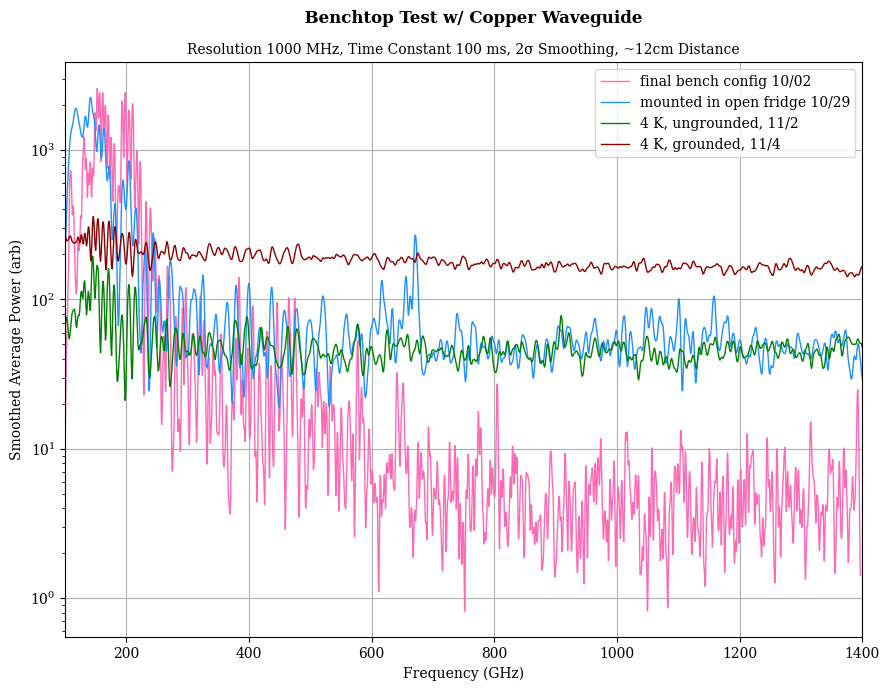

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
cmap = mpl.colormaps['plasma']
c1 = cmap(0.85)
c2 = cmap(0.6)
c3 = cmap(0.4)
c4 = cmap(0.2)

dfs_10_02 = scan_data_1("2026.10.02", "15.52.35")

ax.plot(get_freq(dfs_10_02), gauss_smooth(2, dfs_10_02), label='final bench config 10/02', color="hotpink", lw=1)

#dfs_9_15 = scan_data_1("2026.09.15", "13.12.25")

#ax.plot(get_freq(dfs_9_15), gauss_smooth(2, dfs_9_15), label='no lens', color="hotpink", lw=1)

dfs_10_29 = scan_data_1("2026.10.29", "16.53.27")

ax.plot(get_freq(dfs_10_29), gauss_smooth(2, dfs_10_29), label='mounted in open fridge 10/29', color="dodgerblue", lw=1)

dfs_11_2 = scan_data_1("2026.11.02", "13.34.03")

ax.plot(get_freq(dfs_11_2), gauss_smooth(2, dfs_11_2), label='4 K, ungrounded, 11/2', color='green', lw=1)

#dfs_4_17_2 = scan_data_1("2026.08.11", "11.25.47")

#ax.plot(get_freq(dfs_4_17_2), gauss_smooth(3, dfs_4_17_2), label='vacuum pulled, lens broken 8/11', color='green', lw=1)

dfs_11_4 = scan_data_1("2026.11.04", "16.19.24")

ax.plot(get_freq(dfs_11_4), gauss_smooth(2, dfs_11_4), label='4 K, grounded, 11/4', color='darkred', lw=1)

ax.set_xlim(100,1400)
# ax.grid(axis='y')
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Smoothed Average Power (arb)')
ax.set_yscale('log')
plt.suptitle('          Benchtop Test w/ Copper Waveguide', fontweight='bold')
plt.title('Resolution 1000 MHz, Time Constant 100 ms, 2σ Smoothing, ~12cm Distance', size=10)
#plot_water()
plt.legend()

plt.tight_layout()
#plt.subplots_adjust(top=0.875)  # Adjust the top margin to create space

plt.grid(True)
plt.show()

['Start of Header']
['', 'Date:', '10/02/2026 15:52:35']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1400', 'Resolution(MHz):', '500', 'Time Constant(mS):', '100', 'Number of Scans:', '5']
['', 'Start(cm^-1):', '3.3356', 'Stop(cm^-1):', '46.6990', 'Resolution(cm^-1):', '0.0167', 'Smooth(points):', '0', 'Smooth Type:', 'Average [eg: d(n-2) + d(n-1) + d(n) + d(n+1) + d(n+2)]']
['', 'Note:', '']
['End of Header']

['Start of Header']
['', 'Date:', '10/29/2026 16:53:27']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1500', 'Resolution(MHz):', '1000', 'Time Constant(mS):', '100', 'Number of Scans:', '1']
['', 'Start(cm^-1):', '3.3356', 'Stop(cm^-1):', '50.0346', 'Resolution(cm^-1):', '0.0334', 'Smooth(points):', '0', 'Smooth Type:', 'Average [eg: d(n-2) + d(n-1) + d(n) + d(n+1) + d(n+2)]']
['', 'Note:', '']
['End of Header']

['Start of Header']
['', 'Date:', '11/02/2026 13:34:03']
['', 'Start Frequency(GHz):', '100', 'Stop Frequency(GHz):', '1500', 'Resolu

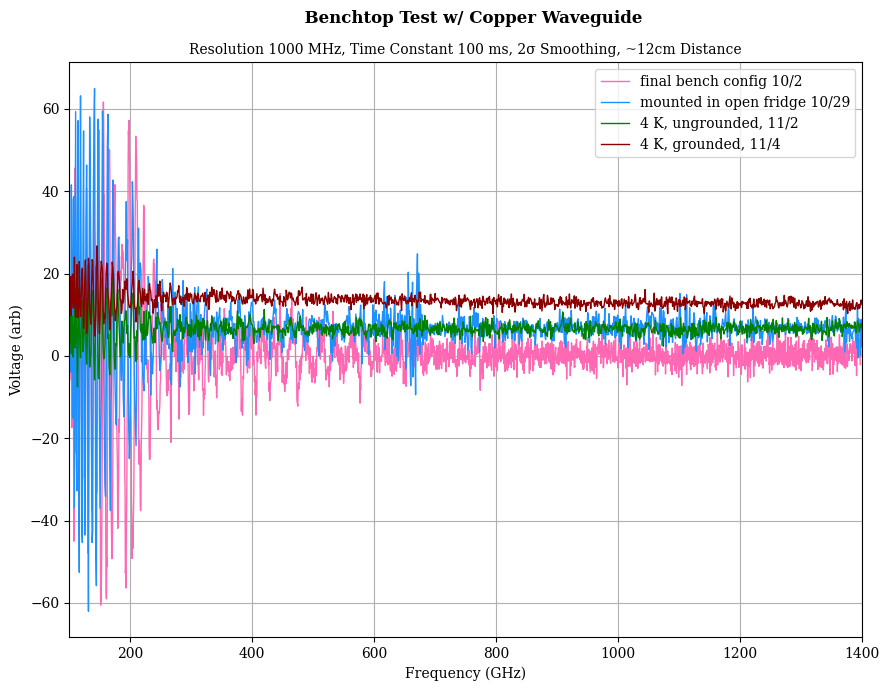

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
cmap = mpl.colormaps['plasma']
c1 = cmap(0.85)
c2 = cmap(0.6)
c3 = cmap(0.4)
c4 = cmap(0.2)

dfs_10_02 = scan_data_1("2026.10.02", "15.52.35")

ax.plot(get_freq(dfs_10_02), get_volt(dfs_10_02), label='final bench config 10/2', color="hotpink", lw=1)

dfs_10_29 = scan_data_1("2026.10.29", "16.53.27")

ax.plot(get_freq(dfs_10_29), get_volt(dfs_10_29), label='mounted in open fridge 10/29', color="dodgerblue", lw=1)

dfs_11_2 = scan_data_1("2026.11.02", "13.34.03")

ax.plot(get_freq(dfs_11_2), get_volt(dfs_11_2), label='4 K, ungrounded, 11/2', color='green', lw=1)

#dfs_4_17_2 = scan_data_1("2026.08.11", "11.25.47")

#ax.plot(get_freq(dfs_4_17_2), gauss_smooth(3, dfs_4_17_2), label='vacuum pulled, lens broken 8/11', color='green', lw=1)

dfs_11_4 = scan_data_1("2026.11.04", "16.19.24")

ax.plot(get_freq(dfs_11_4), get_volt(dfs_11_4), label='4 K, grounded, 11/4', color='darkred', lw=1)

ax.set_xlim(100,1400)
# ax.grid(axis='y')
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Voltage (arb)')
#ax.set_yscale('log')
plt.suptitle('          Benchtop Test w/ Copper Waveguide', fontweight='bold')
plt.title('Resolution 1000 MHz, Time Constant 100 ms, 2σ Smoothing, ~12cm Distance', size=10)
#plot_water()
plt.legend()

plt.tight_layout()
#plt.subplots_adjust(top=0.875)  # Adjust the top margin to create space

plt.grid(True)
plt.show()